# TDSC-ABUS 2023 challenge benchmark

Every paper we reproduce reports this benchmark next to its own protocol, so all methods can be compared with each
other and with the challenge teams. The code is `abus_classification/challenge.py`; this notebook only calls it.

**Source.** G. Luo et al., *Tumor detection, segmentation and classification challenge on automated 3D breast
ultrasound: the TDSC-ABUS challenge*, [arXiv:2501.15588](https://arxiv.org/abs/2501.15588) (Sec. 2.3, 3.3, 4.1), and the organisers'
evaluation code in [PerceptionComputingLab/TDSC-ABUS2023](https://github.com/PerceptionComputingLab/TDSC-ABUS2023)
(`Final_Evaluation/`).

Nothing here trains or tests a network. It uses stored results and the data through `tdsc_abus2023_pytorch`.

## 1. The rules

| Task | Metric | Rule |
|---|---|---|
| Classification | ACC, AUC | Malignant is positive; ACC at p >= 0.5 |
| Segmentation | Dice, HD | Mean per case on the full volume; symmetric Hausdorff distance |
| Detection | FROC | Mean recall at 0.125, 0.25, 0.5, 1, 2, 4, 8 false positives per scan; a hit has IoU > 0.3 |

**Scores.** Norm(x) = (x - min) / (max - min) over the valid teams. Segmentation = (1 + Norm_DICE - Norm_HD) / 2,
classification = (Norm_ACC + Norm_AUC) / 2, detection = Norm_FROC. Overall = the sum of the three (maximum 3),
re-normalised over the teams that completed all three tasks.

**Where the sources are unclear, and what we do:**

| Question | Sources | Ours |
|---|---|---|
| HD units | Not stated. The code uses the image spacing, and the NRRD files store unit spacing | Voxels (`spacing=(1, 1, 1)`). Voxels are not cubes, so this is not millimetres |
| Empty prediction | HD = inf, replaced by 1.05 x the worst valid HD: "all valid results" (Sec. 3.3), per case over all teams (Sec. 4.1) | Per-case team scores are not published, so we use the method's own worst case, or a passed-in value, and report `empty_cases` |
| Ranking | The challenge's Evaluation page ranks (Dice - HD)/2; the paper and its final tables use normalised scores | The paper: it reproduces the published tables (Section 2) |
| Hit rule, FROC grid | Paper: IoU > 0.3. Code also fixes thresholds 0-0.995 in steps of 0.005 and counts repeat hits once | As in the code |
| Box axes | Not stated | X, Y, Z are array axes 2, 1, 0; `mask_box` matches `bbx_labels.csv` (Section 2) |

In [1]:
import sys
sys.path.insert(0, "..")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tdsc_abus2023_pytorch import TDSC, DataSplits
from abus_classification import challenge as c

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
ACCENT, REFERENCE, MALIGNANT, BENIGN = "#4a3aa7", "#a8a69f", "#eb6834", "#2a78d6"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.size": 10, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": AXIS, "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": INK_2,
                     "legend.frameon": False, "figure.dpi": 110})
RESULTS, DATA = Path("../results"), Path("../data/tdsc")
test = TDSC(path=str(DATA), split=DataSplits.TEST, download=False)

## 2. Verification

**Published tables.** From the teams' raw scores, the code must give the paper's Table 7 (overall) and Tables 4-6 (task
scores). The largest difference should only be rounding.

In [2]:
table7 = pd.Series({"T1 SZU": 2.6932, "T2 POSTECH": 1.8854, "T3 HU": 1.7075, "T4 KTH": 1.1995, "T5 EPITA": 0.7758,
                    "T6 FX": 0.5039, "T7 PR": 0.4738})
ours = c.overall_scores(c.PUBLISHED)
assert list(ours.index) == list(table7.index)
print("largest difference from Table 7:", round((ours - table7).abs().max(), 5))
pd.DataFrame({"paper Table 7": table7, "challenge.py": ours.round(4)})

largest difference from Table 7: 0.0001


,paper Table 7,challenge.py
T1 SZU,2.6932,2.6933
T2 POSTECH,1.8854,1.8855
T3 HU,1.7075,1.7074
T4 KTH,1.1995,1.1996
T5 EPITA,0.7758,0.7757
T6 FX,0.5039,0.5040
T7 PR,0.4738,0.4737


**Dice, Hausdorff and boxes on real masks.** We use SciPy instead of adding SimpleITK as a dependency. As a one-off
check on test cases 130, 134 and 150, with a shifted mask and a stray voxel as the prediction, Dice and HD matched
SimpleITK, the library the organisers use, to all printed digits (for example case 130: Dice 0.736504, HD 77.3240).
`mask_box` is checked below against the official box file.

**FROC.** Written after reading the organisers' code and tested by hand in `test/test_challenge.py`. It has **not** been
run side by side with their script: running that downloaded script was blocked on this machine.

In [3]:
boxes = pd.read_csv(DATA / "Test" / "bbx_labels.csv").set_index("id")
for i in (0, 4, 20):
    _, mask, _, _ = test[i]
    case = test.metadata.index[i]
    assert tuple(c.mask_box(mask)) == tuple(boxes.loc[case])
    print(f"case {case}: box {tuple(float(v) for v in c.mask_box(mask))} matches bbx_labels.csv")

case 130: box (205.0, 176.5, 406.0, 38.0, 263.0, 190.0) matches bbx_labels.csv


case 134: box (144.5, 136.0, 595.0, 33.0, 136.0, 110.0) matches bbx_labels.csv


case 150: box (190.0, 323.0, 332.0, 54.0, 278.0, 154.0) matches bbx_labels.csv


**Worked example.** One test lesion with a simulated prediction: the true mask moved by 15 voxels on each axis, plus
one stray voxel. The stray voxel barely changes Dice but dominates HD, which is why the challenge reports both.
Below it, simulated detections show how the FROC curve is read. These are illustrations, not model outputs.

shifted only: Dice 0.345, HD 26.0 voxels;  with one stray voxel: Dice 0.345, HD 132.2 voxels


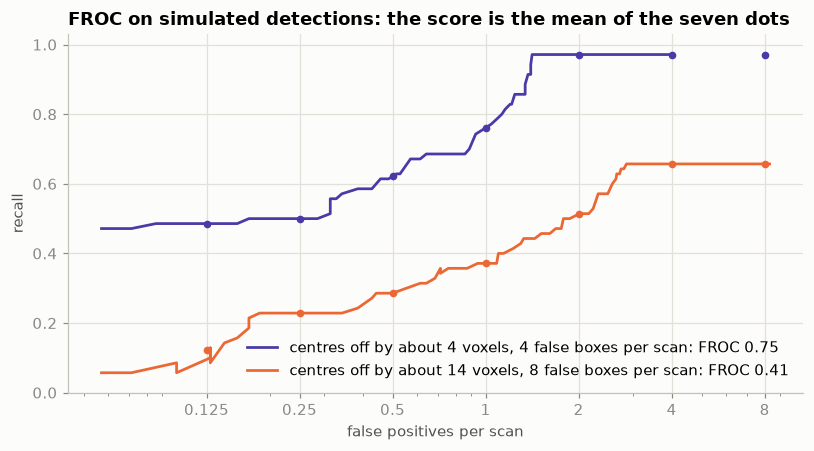

In [4]:
_, mask, _, _ = test[0]
mask = mask > 0
pts = np.argwhere(mask); lo, hi = pts.min(0), pts.max(0)
box = tuple(slice(a, b + 1) for a, b in zip(lo, hi))
pred = np.zeros_like(mask)
pred[tuple(slice(a + 15, b + 16) for a, b in zip(lo, hi))] = mask[box]
without = c.dice_hd(mask, pred)
stray = pred.copy(); stray[lo[0] + 15, min(hi[1] + 120, mask.shape[1] - 1), (lo[2] + hi[2]) // 2] = True
withs = c.dice_hd(mask, stray)
print(f"shifted only: Dice {without[0]:.3f}, HD {without[1]:.1f} voxels;  with one stray voxel: Dice {withs[0]:.3f}, HD {withs[1]:.1f} voxels")

rng = np.random.default_rng(0)
gt = {int(k): [tuple(v)] for k, v in boxes.iterrows()}
def simulate(noise, extra):
    out = {}
    for case, (b,) in gt.items():
        b = np.array(b, float)
        out[case] = [((*(b[:3] + rng.normal(0, noise, 3)), *b[3:]), float(rng.uniform(.5, 1)))]
        out[case] += [((*rng.uniform(50, 500, 3), *b[3:]), float(rng.uniform(0, .8))) for _ in range(extra)]
    return out
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for noise, extra, col in ((4, 4, ACCENT), (14, 8, MALIGNANT)):
    r = c.froc(gt, simulate(noise, extra))
    keep = np.array(r["fp"]) > 0.05
    order = np.argsort(np.array(r["fp"])[keep])
    ax.plot(np.array(r["fp"])[keep][order], np.array(r["recall"])[keep][order], color=col, lw=1.8,
            label=f"centres off by about {noise} voxels, {extra} false boxes per scan: FROC {r['FROC']:.2f}")
    ax.plot(c.KEY_FP, list(r["key_recall"].values()), "o", color=col, ms=4)
ax.set_xscale("log"); ax.set_xticks(c.KEY_FP, [str(k) for k in c.KEY_FP]); ax.set_ylim(0, 1.03)
ax.set_xlabel("false positives per scan"); ax.set_ylabel("recall"); ax.grid(True, color=GRID); ax.set_axisbelow(True)
ax.legend(loc="lower right"); ax.set_title("FROC on simulated detections: the score is the mean of the seven dots")
fig.tight_layout(); plt.show()

## 3. Our methods on the leaderboard

Each method is placed on the published boards as if it had entered alone, which changes the min-max range only if it
sets a new best or worst. Scores come from stored results:

| Method | Source |
|---|---|
| Tan 2012, SVM | `1-tao2013.ipynb`, held-out test split, Section 5, three decimals |
| Tan 2013, LDA | as above |
| Barekatrezaei 2026, voting | `results/eswa2025/`, mean over 3 seeds |
| Zhou 2021, CMSVNetIter | `results/zhou2021/`, mean of 3 seeds' probabilities |

**Classification only for now, and not on equal terms.** Challenge teams had to find the lesion themselves. These
methods use the ground-truth mask, or a patch centred on it. Segmentation and detection need predictions on the full
volume, which none of these runs saved, so those columns and the overall score stay empty.

In [5]:
y = (test.metadata["label"] == "M").to_numpy().astype(int)
zhou = np.mean([np.load(RESULTS / "zhou2021" / f"zhou2021_probs_seed{s}.npy") for s in (0, 1, 2)], 0)
eswa = [pd.read_csv(RESULTS / "eswa2025" / f, index_col=0).loc["Voting"] for f in ("table3_seed0.csv", "results_seed1.csv", "results_seed2.csv")]
METHODS = {
    "Tan 2012, SVM": {"ACC": 0.786, "AUC": 0.862},
    "Tan 2013, LDA": {"ACC": 0.729, "AUC": 0.818},
    "Barekatrezaei 2026, voting": {"ACC": np.mean([e.Acc for e in eswa]), "AUC": np.mean([e.AUC for e in eswa])},
    "Zhou 2021, CMSVNetIter": c.classification(y, zhou),
}
board = c.benchmark(METHODS)
board[["ACC", "AUC", "Cls_Score", "Cls_Rank"]].round(3)

,ACC,AUC,Cls_Score,Cls_Rank
"Tan 2012, SVM",0.786,0.862,0.958,1/9
"Tan 2013, LDA",0.729,0.818,0.824,2/9
"Barekatrezaei 2026, voting",0.752,0.859,0.942,2/9
"Zhou 2021, CMSVNetIter",0.629,0.666,0.353,6/9


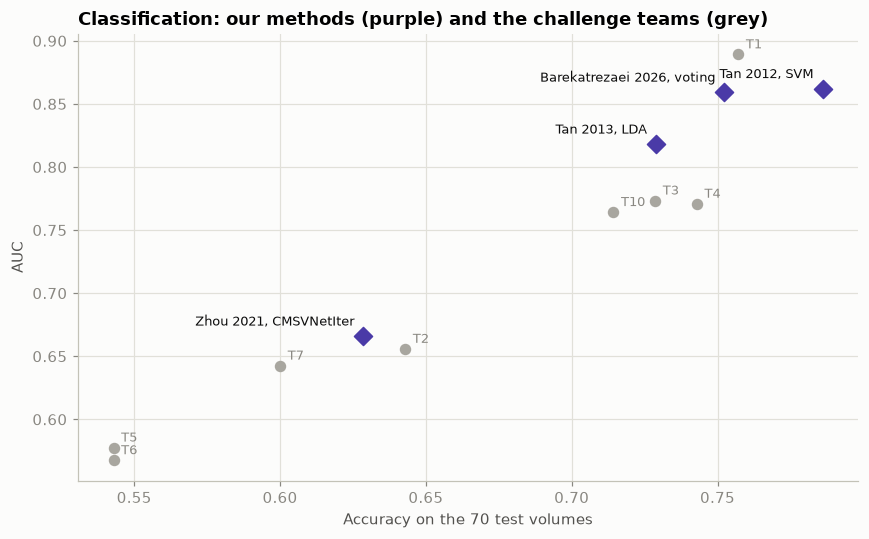

In [6]:
teams = c.PUBLISHED[["ACC", "AUC"]].dropna()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(teams.ACC, teams.AUC, s=42, color=REFERENCE, zorder=3)
for name, row in teams.iterrows():
    ax.annotate(name.split()[0], (row.ACC, row.AUC), xytext=(5, 4), textcoords="offset points", fontsize=8.5, color=MUTED)
ax.scatter(board.ACC, board.AUC, s=70, color=ACCENT, marker="D", zorder=4)
for name, row in board.iterrows():
    ax.annotate(name, (row.ACC, row.AUC), xytext=(-6, 7), textcoords="offset points", fontsize=8.5, color=INK, ha="right")
ax.set_xlabel("Accuracy on the 70 test volumes"); ax.set_ylabel("AUC"); ax.grid(True, color=GRID); ax.set_axisbelow(True)
ax.set_title("Classification: our methods (purple) and the challenge teams (grey)")
fig.tight_layout(); plt.show()

## 4. How to add a paper

Save, on Kaggle, the classification probabilities and, if the method does them, the full-volume masks and detection
boxes. Then, in the paper's notebook:

```python
from abus_classification import challenge as c
results = {**c.classification(y, probabilities),                    # y: 1 = malignant, cases in TDSC Test order
           **c.segmentation([c.dice_hd(gt, pred) for gt, pred in masks]),
           **c.froc(boxes, predictions)}                            # boxes from bbx_labels.csv or c.mask_box
c.benchmark({"Author 2024": results})
```

State in the notebook whether the method located the lesion itself or used the ground truth.